# Q-Relay Mission: the three problems as one pipeline
**QRNG → Teleportation → Distributed Deutsch–Jozsa.** The QRNG seeds a Haar-random secret state and a hidden oracle. Alice teleports the state to Bob. Then Alice teleports a $|-\rangle$ to Bob, which **becomes the DJ ancilla**. Bob queries the hidden oracle once. One noise knob affects all three stages.

In [1]:
import sys, json, math, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import numpy as np, matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})
def sweep(name): return json.load(open(f'../data/sweeps/{name}.json'))
from qrelay import dj, distributed_dj, teleport, plots
from qrelay.mission import run_mission, MissionConfig
from qrelay.noise import NoiseSpec

## 1. The distributed DJ circuit (teleported ancilla, dynamic circuit)

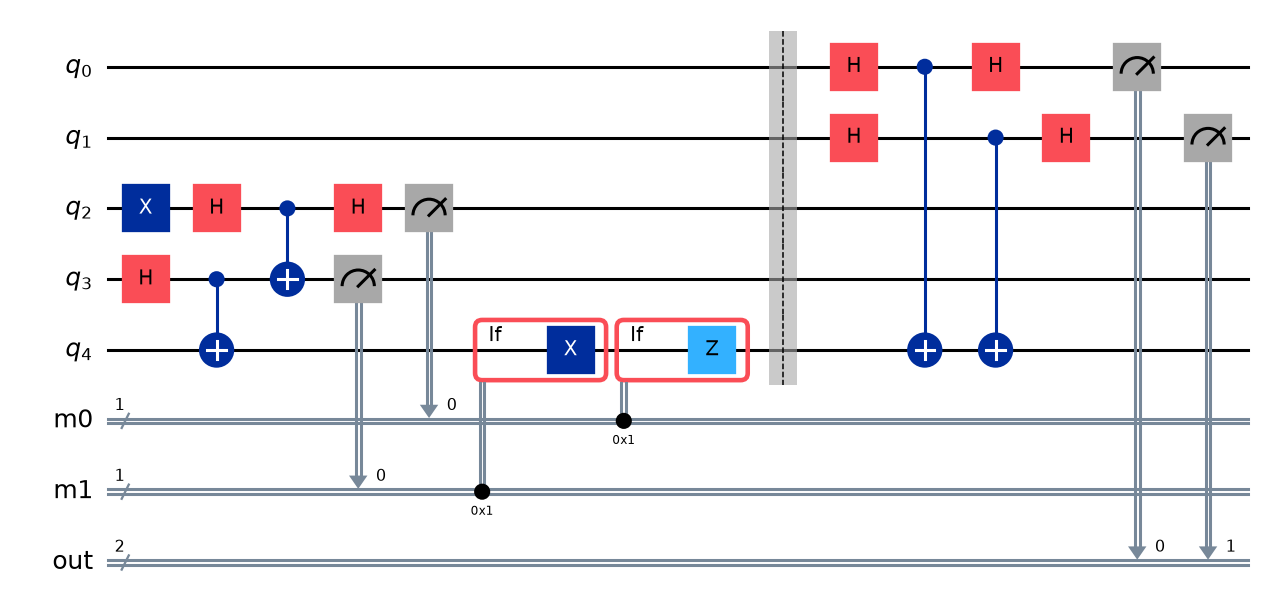

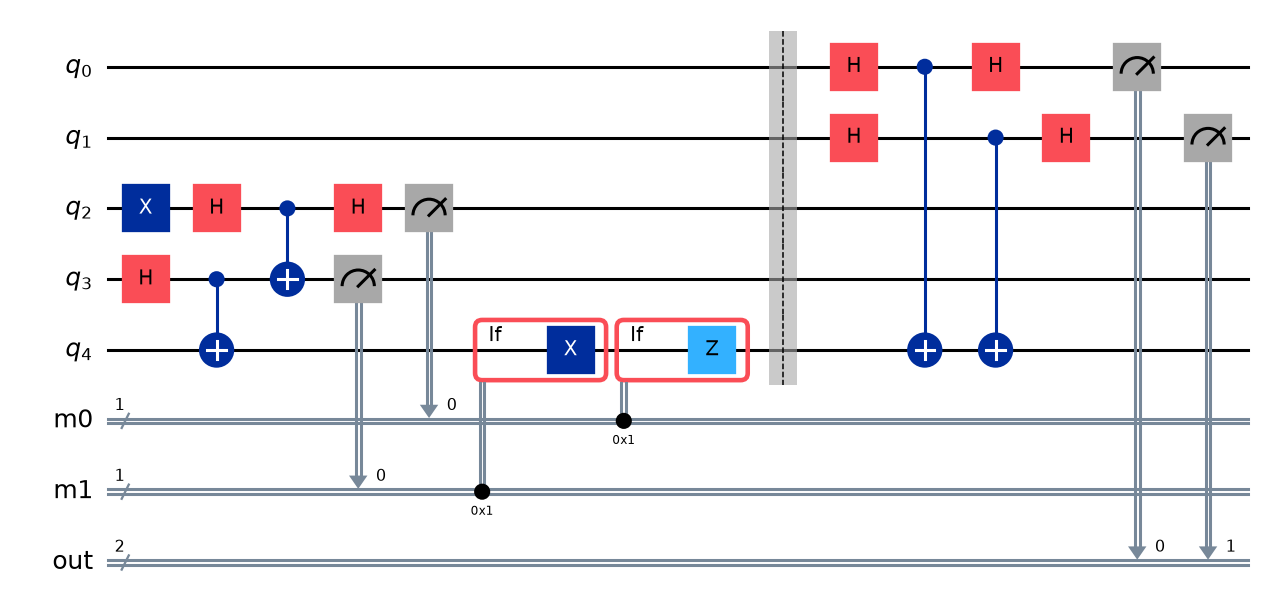

In [2]:
distributed_dj.distributed_dj_circuit(dj.parity(2)).draw('mpl', fold=-1)

## 2. Run a mission (the same event generator drives the web app's WebSocket)

In [3]:
for ev in run_mission(MissionConfig(n=3, noise_level=0.0, seed=7, shots=1024)):
    print(f"[{ev['t']:6.2f}s] {ev['type']:20s} {ev['caption'][:110]}")
summary = ev['data']; summary

[  0.00s] mission_start        Q-Relay mission start: QRNG -> teleportation -> distributed Deutsch-Jozsa.


[  2.29s] qrng_batch           Entropy pool charged: 8192 bits from 16 qubits in superposition (H then measure). Source: SIM.
[  2.29s] health_test          Health tests passed: monobit, runs, block frequency (passing means no bias was detected — not a proof of rando
[  2.29s] state_drawn          QRNG draws a Haar-random secret state: theta=1.407, phi=2.249.
[  2.29s] oracle_chosen        QRNG secretly picks a hidden oracle on n=3 input bits. Nobody (including Bob) knows whether it is constant or 
[  2.30s] bell_pair            Hadamard on q1 puts it in superposition.
[  2.30s] bell_pair            CNOT entangles q1 and q2 into a Bell pair; both arrows shrink to the centre: each qubit alone is maximally mix
[  2.30s] alice_bsm            Alice applies CNOT(q0 -> q1): |psi> becomes entangled with the pair.
[  2.30s] alice_bsm            Hadamard on q0 completes the rotation into the Bell basis.
[  2.30s] alice_bsm            Alice measures: m0=1, m1=1. q0's original state is destroyed 

{'theta': 1.4067057919709687,
 'phi': 2.2492107873798917,
 'fidelity': 0.9999999999999999,
 'tomography_fidelity': 0.9780021510286563,
 'ancilla_fidelity': 1.0000000000000002,
 'n': 3,
 'oracle': 'ip_011',
 'verdict': 'balanced',
 'truth': 'balanced',
 'correct': True,
 'success_probability': 1.0,
 'bits_used': 224,
 'pool_log': ['53 bits -> haar cos(theta)',
  '53 bits -> haar phi',
  'randint(6) -> oracle choice'],
 'noise_level': 0.0,
 'source': 'SIM'}

## 3. The same mission under noise

In [4]:
for lvl in (0.2, 0.6, 0.9):
    s = list(run_mission(MissionConfig(n=3, noise_level=lvl, seed=7, shots=1024)))[-1]['data']
    print(f"noise={lvl:.1f}: teleport F={s['fidelity']:.3f} ({'quantum' if s['fidelity']>2/3 else 'CLASSICAL'}), ancilla F={s['ancilla_fidelity']:.3f}, DJ verdict={s['verdict']} truth={s['truth']} P(success)={s['success_probability']:.3f}")

noise=0.2: teleport F=0.846 (quantum), ancilla F=0.856, DJ verdict=balanced truth=balanced P(success)=0.864


noise=0.6: teleport F=0.672 (quantum), ancilla F=0.685, DJ verdict=balanced truth=balanced P(success)=0.793


noise=0.9: teleport F=0.589 (CLASSICAL), ancilla F=0.599, DJ verdict=balanced truth=balanced P(success)=0.775


## 4. How teleportation fidelity limits DJ correctness
**Claim (proved in THEORY.md):** with a noiseless oracle, constant oracles are always classified correctly, and for a balanced oracle
$$P(\text{success}) = \langle -|\rho_{anc}|-\rangle,$$
the teleportation fidelity of the $|-\rangle$ ancilla. A $|+\rangle$ component gives no phase kickback and leaves the inputs in $|0\dots0\rangle$. We check this numerically:

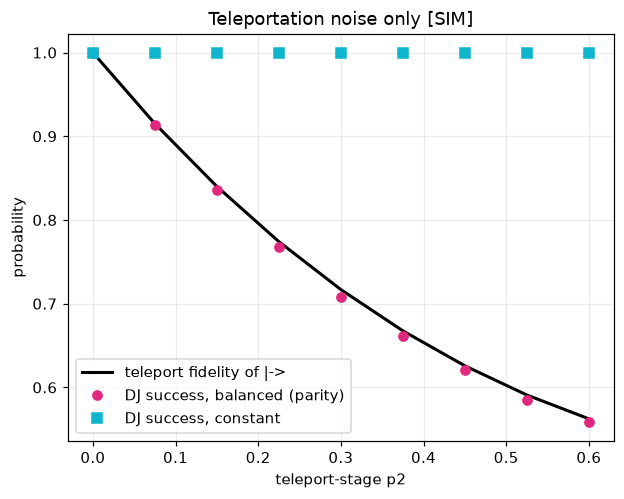

max |P(success, balanced) - F_anc| = 0.008753537986218363


In [5]:
ps = np.linspace(0, 0.6, 9); anc, bal, const = [], [], []
for p in ps:
    spec = NoiseSpec(p1=p/10, p2=p) if p > 0 else None
    anc.append(teleport.exact_fidelity(math.pi/2, math.pi, spec, shots=2000)['fidelity'])
    bal.append(distributed_dj.run_distributed(dj.parity(3), shots=20000, tele_noise=spec)['success_probability'])
    const.append(distributed_dj.run_distributed(dj.constant_one(3), shots=4000, tele_noise=spec)['success_probability'])
plt.plot(ps, anc, 'k-', lw=2, label='teleport fidelity of |->'); plt.plot(ps, bal, 'o', color=plots.MAGENTA, label='DJ success, balanced (parity)')
plt.plot(ps, const, 's', color=plots.CYAN, label='DJ success, constant'); plt.xlabel('teleport-stage p2'); plt.ylabel('probability'); plt.legend(); plt.title('Teleportation noise only [SIM]'); plt.show()
print('max |P(success, balanced) - F_anc| =', np.max(np.abs(np.array(bal) - np.array(anc))))

## 5. Which stage hurts more? (noise confined to teleportation vs to the oracle)

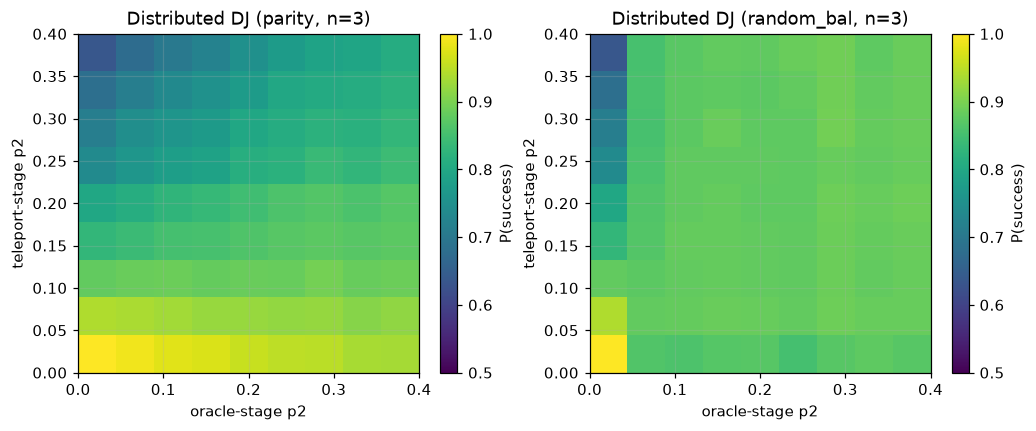

In [6]:
h = sweep('dist_dj_heatmap')
fig, ax = plt.subplots(1, 2, figsize=(11, 4)); plots.stage_heatmap(h['parity'], ax=ax[0]); plots.stage_heatmap(h['random_bal'], ax=ax[1]); plt.show()

## Conclusions
* In the ideal case the teleported ancilla is indistinguishable from a local one (checked for every library oracle, n ≤ 4, in both circuit variants).
* Teleportation noise affects only the **balanced** verdicts, in exact proportion to the ancilla's teleportation fidelity. Oracle noise affects both kinds, and grows with oracle depth.
* One physical quantity, channel fidelity, links PS1 directly to PS3. PS2 supplies the randomness for the states and oracles.